# Global 90/60 + Managed Futures

Compare two-thirds NTSG-inspired core plus one-third managed futures with 60/40 and 100% developed-world stocks. The investor is assumed to have access to both UCITS and US ETFs, with USD funding, reinvested distributions and no personal capital-gains tax.

**Edit cell 2, then Run All.** Defaults were audited on 10 November 2026; [the decision record](methodology/realistic_backtest.md) documents every assumption, source and uncertainty. Starting in 2000 avoids the less comparable AQR/BTOP50 segments in the main result. Select 1985 to study the longer synthetic scenario, not an actual ETF history.

## Synthetic and observed returns

Before each ETF's first full return month, use a documented proxy: World net equity index, developed unhedged government cash bonds, and SG CTA (AQR/BTOP50 only in the extended sample). Current ETF fees are hypothetical pre-inception cost budgets, not historical fee schedules. Actual NTSG, URTH, IGLO and DBMF returns replace proxies when available and already include fund costs. No TER, synthetic futures drag or CTA gross-up is added to their observed returns.

The synthetic core is a funded-bond approximation. At target weights its monthly return is approximately

$$
R_t=0.90R_{E,t}+0.60R_{B,t}-0.50R_{f,t}-C_t.
$$

USD bills are a financing reference, not executable repo. The 0.5% bond-notional drag is an explicitly unverified implementation allowance; it is not a second full financing rate. The proxy omits actual futures contracts, multicurrency collateral, ESG selection and daily margin. Month-end 5-percentage-point resets only approximate the fund's exceptional resets.

## Fair comparisons and costs

Two-thirds times 90/60 yields 60% equity and 40% bond exposure plus a funded one-third managed-futures sleeve. Its embedded borrowing and the CTA's own futures remain internal. Investor transaction costs are charged only on initial purchases and dollars bought/sold at portfolio resets. They are separate from internal fund costs. No end-date liquidation is assumed by default. Displayed capital is a scalable fractional-unit model, not a whole-share brokerage simulation.

NTSG's NAV diagnostic remains uncalibrated and uses full available source history. CTA high-water marks also retain full source history, regardless of the selected comparison dates. The short observed-ETF panel is shown separately; the long research panel must not be described as a live tradable track record.

In [1]:
# Parameters: annual costs are decimal rates; dates select return months.
from pathlib import Path

DATA = Path("data")
start_date = "2000-01-01"
end_date = None  # None uses the latest common completed month.
initial_value = 100000.0
rebalance_months = (2, 5, 8, 11)

# Portfolio exposures and annual costs.
core_weight = 2 / 3
core_equity_weight = 0.90
core_bond_weight = 0.60
benchmark_equity_weight = 0.60
benchmark_bond_weight = 0.40
fund_ter = 0.0025
annual_drag = 0.005  # Per unit of 90/60 bond notional.
equity_annual_ter = 0.0024  # URTH; applied only before observed ETF returns.
bond_annual_ter = 0.0020  # IGLO; G7 rather than the historical WGBI proxy.
dbmf_ter = 0.0085
cta_management_fee = 0.02
cta_performance_fee = 0.20
use_cta_gross_up = False  # Aggregate fee inversion is a sensitivity, not verified alpha.
aqr_annual_drag = 0.005  # Unverified transaction-cost allowance; extended sample only.
use_actual_core = True
use_actual_benchmarks = True
exceptional_rebalance_band = 0.05  # Month-end approximation; actual fund may reset intramonth.

# Investor execution costs per dollar bought or sold, not annual TERs.
core_trading_cost = 0.0025  # 25 bp: UCITS execution/commission allowance, not measured history.
equity_trading_cost = 0.0005  # 5 bp: URTH half-spread plus execution allowance.
bond_trading_cost = 0.0010  # 10 bp: IGLO allowance.
mf_trading_cost = 0.0010  # 10 bp: DBMF allowance.
trading_cost_multiplier = 1.0
trading_cost_scenarios = (0.5, 1.0, 2.0)
liquidate_at_end = False

# Historical proxy boundaries; observed DBMF starts at its first full return month.
btop_start = "1987-01-31"
sg_start = "2000-01-31"
use_actual_dbmf = True
validation_drag = 0.0
validation_drag_scenarios = (0.0, 0.005, 0.01)

#for cost sensitivity chart
drag_sensitivity_min = 0.0
drag_sensitivity_max = 0.01
drag_sensitivity_points = 21

# Analysis windows and chart settings.
rolling_months = (12, 60, 120)
correlation_months = 24
regime_months = 12
bull_return_threshold = 0.0
histogram_bins = 30

# Local source files.
equity_file = "MSCI_WORLD_NET_USD_MONTHLY.CSV"
bond_file = "FTSE_WGBI_DM_USD_UNHEDGED_MONTHLY.CSV"
cash_file = "FRENCH_USD_BILL_MONTHLY.CSV"
nav_file = "NTSG_NAV_USD_WISDOMTREE.CSV"
managed_futures_file = "MANAGED_FUTURES_MONTHLY.CSV"
dbmf_file = "DBMF_ACTUAL.CSV"
fx_file = "EURUSD_CURVO_MONTHLY.CSV"
core_actual_file = "NTSG_ACTUAL_USD.CSV"
equity_actual_file = "URTH_ACTUAL.CSV"
bond_actual_file = "IGLO_ACTUAL_USD.CSV"

## Validation of the uncalibrated proxy against official NTSG NAV


In [2]:
import warnings

import numpy as np
import pandas as pd
from IPython.display import display
from helpers.portfolio_implementation import rebalance_portfolio, splice_actual_returns

warnings.filterwarnings("ignore", message="Sorting by default when concatenating all DatetimeIndex is deprecated.*")


def load_prices(filename):
    prices = pd.read_csv(DATA / filename, parse_dates=["date"])
    prices = prices.set_index("date")["adjusted_price"].sort_index()
    if prices.index.has_duplicates or prices.isna().any() or not np.isfinite(prices).all() or (prices <= 0).any():
        raise ValueError(f"Invalid prices in {filename}")
    return prices


def quarterly_returns(data, equity_weight, bond_weight, monthly_fee=0.0, annual_drag=0.0):
    equity = initial_value * equity_weight
    bond = initial_value * bond_weight
    cash = initial_value - equity - bond
    monthly_returns = []
    for date, row in data.iterrows():
        start_nav = equity + bond + cash
        if start_nav <= 0:
            raise ValueError("Portfolio NAV must remain positive")
        fee = start_nav * monthly_fee + bond * annual_drag / 12
        equity *= 1 + row["equity"]
        bond *= 1 + row["bond"]
        cash = cash * (1 + row["risk_free"]) - fee
        nav = equity + bond + cash
        if nav <= 0:
            raise ValueError("Portfolio NAV must remain positive")
        monthly_returns.append(nav / start_nav - 1)
        off_target = exceptional_rebalance_band is not None and (
            abs(equity / nav - equity_weight) > exceptional_rebalance_band
            or abs(bond / nav - bond_weight) > exceptional_rebalance_band)
        if date.month in rebalance_months or off_target:
            equity = nav * equity_weight
            bond = nav * bond_weight
            cash = nav - equity - bond
    return pd.Series(monthly_returns, index=data.index)


levels = pd.concat({
    "equity": load_prices(equity_file),
    "bond": load_prices(bond_file),
    "risk_free": load_prices(cash_file),
}, axis=1, sort=True)
start = max(levels[column].first_valid_index() for column in levels)
end = min(min(levels[column].last_valid_index() for column in levels),
          pd.Timestamp.today().to_period("M").start_time - pd.offsets.MonthEnd(1))
levels = levels.reindex(pd.date_range(start, end, freq="ME"))
if levels.isna().any().any():
    raise ValueError("Missing monthly index levels in the common history")
full_returns = levels.pct_change(fill_method=None).dropna()
returns = full_returns
fund_cost = 1 - (1 - fund_ter) ** (1 / 12)

nav_prices = load_prices(nav_file)
nav_monthly = nav_prices.resample("ME").last()
nav_observation_dates = pd.Series(nav_prices.index, index=nav_prices.index).resample("ME").last()
if pd.Timestamp.today().normalize() <= nav_monthly.index[-1]:
    nav_monthly = nav_monthly.iloc[:-1]
    nav_observation_dates = nav_observation_dates.iloc[:-1]
nav_returns = nav_monthly.pct_change(fill_method=None).rename("NTSG_NAV")
proxy_returns = quarterly_returns(returns, core_equity_weight, core_bond_weight, fund_cost, validation_drag).rename("NTSG_proxy")
comparison = pd.concat([proxy_returns, nav_returns], axis=1).dropna()
if comparison.empty or not comparison.index.equals(pd.date_range(comparison.index[0], comparison.index[-1], freq="ME")):
    raise ValueError("Missing or non-contiguous NAV comparison returns")
difference = comparison["NTSG_proxy"] - comparison["NTSG_NAV"]
wealth = (1 + comparison).cumprod()
print(f"NAV comparison: {comparison.index[0]:%Y-%m} to {comparison.index[-1]:%Y-%m} ({len(comparison)} months)")
print(f"Monthly correlation: {comparison.corr().iloc[0, 1]:.4f}")
print(f"Annualized tracking error: {difference.std(ddof=1) * 12 ** 0.5:.2%}")
print(f"Monthly return RMSE: {difference.pow(2).mean() ** 0.5:.2%}")
print(f"NAV already includes fund expenses; the uncalibrated proxy uses {validation_drag:.2%} drag per bond notional.")
display(pd.DataFrame({
    "NAV observation date": nav_observation_dates.reindex(comparison.index),
    "Proxy monthly return": comparison["NTSG_proxy"],
    "NAV monthly return": comparison["NTSG_NAV"],
    "Proxy growth": wealth["NTSG_proxy"],
    "NAV growth": wealth["NTSG_NAV"],
}))


NAV comparison: 2024-12 to 2026-08 (21 months)
Monthly correlation: 0.9902
Annualized tracking error: 1.75%
Monthly return RMSE: 0.49%
NAV already includes fund expenses; the uncalibrated proxy uses 0.00% drag per bond notional.


,NAV observation date,Proxy monthly return,NAV monthly return,Proxy growth,NAV growth
2024-12-31,2024-12-31,-0.039437,-0.039329,0.960563,0.960671
2025-01-31,2025-01-31,0.030411,0.034622,0.989775,0.993932
2025-02-28,2025-02-28,0.002088,0.006955,0.991841,1.000845
2025-03-31,2025-03-31,-0.037627,-0.042481,0.954521,0.958329
2025-04-30,2025-04-30,0.027882,0.020107,0.981135,0.977597
2025-05-31,2025-05-30,0.043325,0.040894,1.023643,1.017575
2025-06-30,2025-06-30,0.048410,0.045390,1.073197,1.063763
2025-07-31,2025-07-31,-0.000802,0.001495,1.072337,1.065353
2025-08-31,2025-08-29,0.027433,0.030128,1.101754,1.097450
2025-09-30,2025-09-30,0.032983,0.030583,1.138093,1.131014


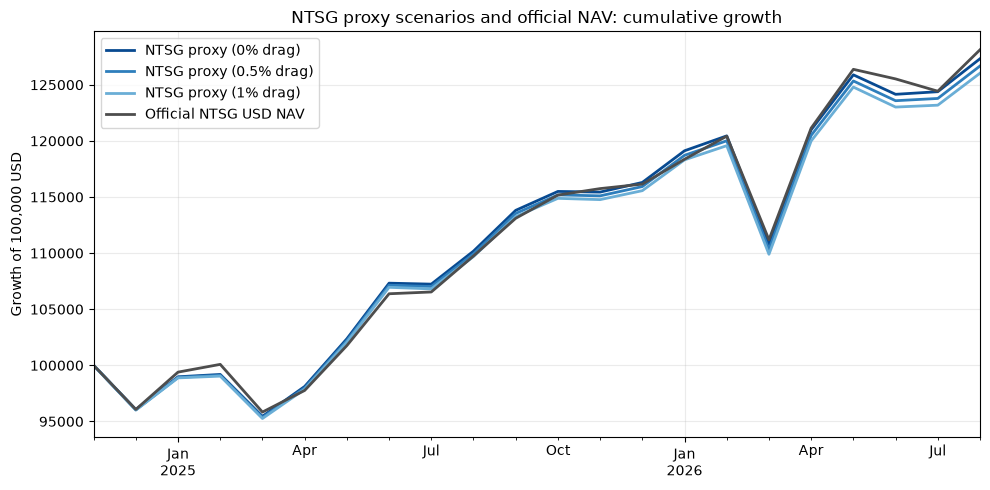

In [3]:
import matplotlib.pyplot as plt

scenario_names = [f"NTSG proxy ({drag * 100:g}% drag)" for drag in validation_drag_scenarios]
proxy_colors = dict(zip(scenario_names, plt.cm.Blues(np.linspace(0.9, 0.5, len(scenario_names)))))
portfolio_colors = {**proxy_colors, "60/40": "#b35806", "100% equities": "#4d4d4d"}
proxy_styles = dict.fromkeys(scenario_names, "-")
plot_returns = pd.DataFrame({
    name: quarterly_returns(full_returns, core_equity_weight, core_bond_weight, fund_cost, drag).loc[comparison.index]
    for name, drag in zip(scenario_names, validation_drag_scenarios)
})
plot_returns["Official NTSG USD NAV"] = comparison["NTSG_NAV"]
plot_wealth = initial_value * (1 + plot_returns).cumprod()
plot_wealth.loc[plot_wealth.index[0] - pd.offsets.MonthEnd(1)] = initial_value
plot_wealth = plot_wealth.sort_index()
ax = plot_wealth.plot(figsize=(10, 5), linewidth=2, color=[*proxy_colors.values(), "#4d4d4d"])
ax.set_title("NTSG proxy scenarios and official NAV: cumulative growth")
ax.set_xlabel("")
ax.set_ylabel(f"Growth of {initial_value:,.0f} USD")
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

The diagnostic uses official USD NAV, not exchange closing prices. The portfolio comparison uses the NTSG USD listing's adjusted close after its first complete month; NAV/market-price and valuation-time differences can matter. Synthetic returns are not fitted to the short NAV overlap.

## Managed futures: sources and historical DBMF proxy

| Source | Downloaded history | Role and limitation |
| --- | --- | --- |
| [AQR TSMOM](https://www.aqr.com/Insights/Datasets/Time-Series-Momentum-Factors-Monthly) | 1985 onward | Hypothetical excess returns; add USD bills for funded total returns. Transaction-cost deductions are not verified. |
| [BarclayHedge BTOP50](https://portal.barclayhedge.com/cgi-bin/indices/displayHfIndex.cgi?indexCat=Barclay-Investable-Benchmarks&indexName=BTOP50-Index) | 1987 onward | Net manager returns; extends the broad CTA history. BarclayHedge is not Barclays Bank. |
| [SG CTA and SG Trend](https://ionanalytics.com/barclayhedge/indices/) | 2000 onward | Net manager returns; daily returns compounded to monthly. SG CTA is the closest conceptual fit to DBMF's broad leading-CTA replication; SG Trend is a narrower trend comparator. |
| [DBMF](https://www.imgp.com/us/dbmf/) | May 2019 onward | Adjusted market-close total returns, already net of expenses; first full monthly return is June 2019. Current TER: 0.85%. |

The default sample starts with SG CTA in 2000 and switches to actual DBMF in June 2019. AQR through 1986 and BTOP50 during 1987–1999 are retained only if an earlier comparison start is selected. Aggregate gross-up is OFF by default and shown as a sensitivity. The downloaded AQR factor begins in 1985, not 1980; no pre-1985 observations are invented. These are different strategies, risk targets and manager universes, not a verified reconstruction of DBMF. The overlap comparison below is diagnostic only: no return or volatility calibration is fitted to DBMF.

For net CTA indices, invert an assumed monthly 2/20 fee schedule using the index's own net-NAV high-water mark from source inception. Management fees are 2%/12 of opening NAV; incentive fees crystallize monthly only above the previous high-water mark. The fee estimate is computed on the original full index before taking the required segment. This cannot recover manager-level fees or high-water marks. Subtract 0.85%/12 only from synthetic months; the sensitivity skips gross-up but retains that proxy TER. AQR receives no CTA fee gross-up; USD cash is added only to its excess returns and a configurable 0.5% annual transaction-cost allowance is deducted. This allowance is not a verified AQR cost schedule.

Sources, retrieval dates and limitations are in [the manifest](data/managed_futures_sources_manifest.json). Refresh inputs with `python -m helpers.download_managed_futures_data`.

In [4]:
def gross_up_cta(net_returns, management_fee=cta_management_fee, performance_fee=cta_performance_fee):
    if not 0 <= management_fee < 1 or not 0 <= performance_fee < 1:
        raise ValueError("Invalid CTA fee assumptions")
    if net_returns.isna().any() or not np.isfinite(net_returns).all() or (net_returns <= -1).any():
        raise ValueError("Invalid CTA net returns")
    nav = high_water_mark = 1.0
    gross_returns = []
    for net_return in net_returns:
        end_nav = nav * (1 + net_return)
        incentive_fee = max(end_nav - high_water_mark, 0) * performance_fee / (1 - performance_fee)
        gross_returns.append((end_nav + incentive_fee) / nav - 1 + management_fee / 12)
        nav = end_nav
        high_water_mark = max(high_water_mark, nav)
    return pd.Series(gross_returns, index=net_returns.index)


mf_inputs = pd.read_csv(DATA / managed_futures_file, parse_dates=["date"]).set_index("date")
if mf_inputs.index.has_duplicates or not mf_inputs.index.is_monotonic_increasing:
    raise ValueError("Invalid managed-futures dates")
cta_indices = {"BTOP50": mf_inputs["btop50_net"].dropna(),
               "SG CTA": mf_inputs["sg_cta_net"].dropna(),
               "SG Trend": mf_inputs["sg_trend_net"].dropna()}
cta_gross = {name: gross_up_cta(series, cta_management_fee, cta_performance_fee)
             for name, series in cta_indices.items()}
aqr_total = mf_inputs["aqr_excess"].dropna().add(full_returns["risk_free"]).dropna() - aqr_annual_drag / 12
mf_proxy = pd.concat([aqr_total.loc[aqr_total.index < pd.Timestamp(btop_start)], cta_gross["BTOP50"].loc[lambda series: (series.index >= pd.Timestamp(btop_start)) & (series.index < pd.Timestamp(sg_start))],
                      cta_gross["SG CTA"].loc[sg_start:]]) - dbmf_ter / 12
mf_proxy_no_gross = pd.concat([aqr_total.loc[aqr_total.index < pd.Timestamp(btop_start)], cta_indices["BTOP50"].loc[lambda series: (series.index >= pd.Timestamp(btop_start)) & (series.index < pd.Timestamp(sg_start))],
                               cta_indices["SG CTA"].loc[sg_start:]]) - dbmf_ter / 12
dbmf_prices = load_prices(dbmf_file)
dbmf_prices = dbmf_prices.loc[dbmf_prices.index < pd.Timestamp.today().to_period("M").start_time]
dbmf_actual = dbmf_prices.resample("ME").last().pct_change(fill_method=None).dropna()
splice_date = dbmf_actual.index[0]
managed_futures_gross = splice_actual_returns(mf_proxy.reindex(full_returns.index), dbmf_actual, use_actual_dbmf)
managed_futures_no_gross = splice_actual_returns(mf_proxy_no_gross.reindex(full_returns.index), dbmf_actual, use_actual_dbmf)
managed_futures = managed_futures_gross if use_cta_gross_up else managed_futures_no_gross
if managed_futures.isna().any() or managed_futures_no_gross.isna().any():
    raise ValueError("Missing managed-futures months in the common portfolio history")

candidate_returns = {"AQR TSMOM": aqr_total - dbmf_ter / 12,
                     **{name: series - dbmf_ter / 12 for name, series in cta_gross.items()}}
mf_validation = pd.concat({**candidate_returns, "DBMF": dbmf_actual}, axis=1).dropna()
mf_validation_rows = []
for name, series in candidate_returns.items():
    sample = mf_validation[name]
    mf_validation_rows.append({"Candidate": name, "History starts": series.index[0].strftime("%Y-%m"),
                               "History ends": series.index[-1].strftime("%Y-%m"),
                               "Correlation to DBMF": f"{sample.corr(mf_validation['DBMF']):.2f}",
                               "Tracking error": f"{(sample - mf_validation['DBMF']).std(ddof=1) * 12 ** 0.5:.2%}",
                               "Volatility": f"{sample.std(ddof=1) * 12 ** 0.5:.2%}"})
print(f"Candidate validation: {mf_validation.index[0]:%Y-%m} to {mf_validation.index[-1]:%Y-%m}; all candidates use the same months.")
print(f"Actual DBMF available from {splice_date:%Y-%m}; splice enabled: {use_actual_dbmf}. No second TER on observed returns.")
display(pd.DataFrame(mf_validation_rows).set_index("Candidate"))

Candidate validation: 2019-06 to 2026-05; all candidates use the same months.
Actual DBMF available from 2019-06; splice enabled: True. No second TER on observed returns.


,History starts,History ends,Correlation to DBMF,Tracking error,Volatility
Candidate,,,,,
AQR TSMOM,1985-02,2026-05,0.60,11.34%,13.63%
BTOP50,1987-01,2026-10,0.86,5.91%,8.41%
SG CTA,2000-01,2026-10,0.86,5.81%,9.44%
SG Trend,2000-01,2026-10,0.86,6.34%,12.10%


### Comparison of 90/60 + managed futures, 60/40 and stocks

Monthly USD returns: 2000-01 to 2026-08
Allocation: 66.67% in 90/60 + 33.33% managed futures; reset months: (2, 5, 8, 11).
Synthetic 90/60: 0.25% fee + 0.50% drag per bond notional; actual NTSG used: True.
Gross-up enabled: False; actual benchmark funds used: True.
Actual ETF returns already include expenses. Investor entry and turnover costs are charged separately; no personal capital-gains tax.


,90/60 + managed futures,60/40,100% equities
2000-01-31,-0.039564,-0.044381,-0.058041
2000-02-29,-0.002957,0.001723,0.002376
2000-03-31,0.041088,0.049251,0.068781
2000-04-30,-0.046007,-0.039316,-0.042589
2000-05-31,-0.011980,-0.010183,-0.025631
...,...,...,...
2026-04-30,0.059815,0.057436,0.091823
2026-05-31,0.039252,0.026550,0.042635
2026-06-30,-0.001411,-0.005090,-0.004562
2026-07-31,0.012450,-0.001316,0.003602


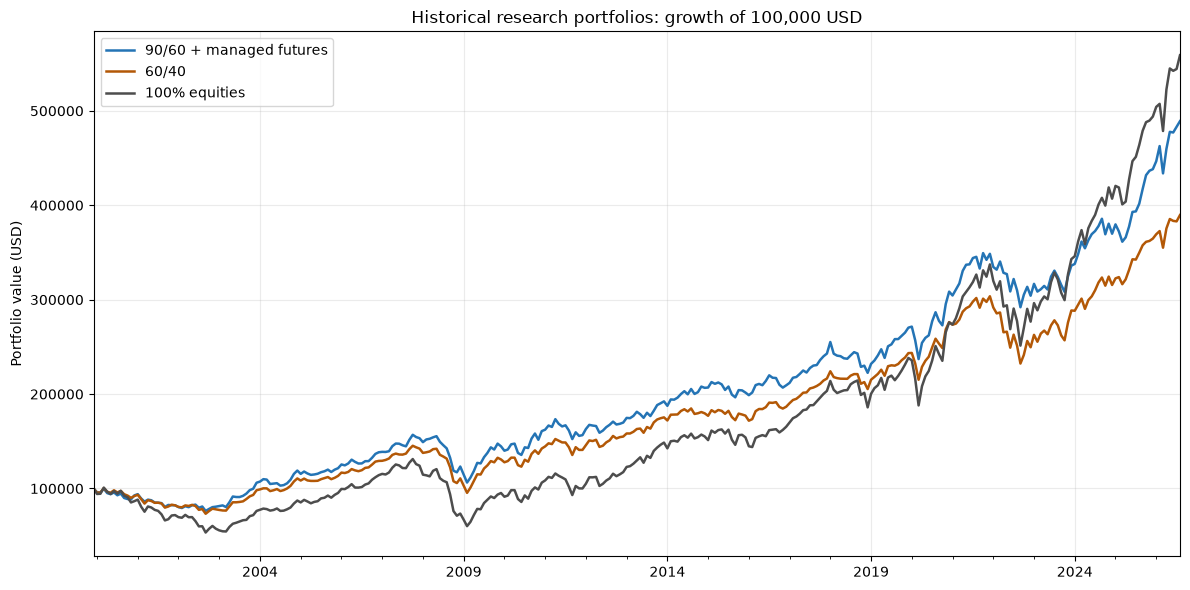

In [5]:
def actual_monthly_returns(filename):
    prices = load_prices(filename)
    prices = prices.loc[prices.index < pd.Timestamp.today().to_period("M").start_time]
    return prices.resample("ME").last().pct_change(fill_method=None).dropna()


core_actual = actual_monthly_returns(core_actual_file)
equity_actual = actual_monthly_returns(equity_actual_file)
bond_actual = actual_monthly_returns(bond_actual_file)
returns = full_returns.loc[start_date:end_date]
if len(returns) < 2:
    raise ValueError("Select at least two return months within the common history")
managed_futures = managed_futures.reindex(returns.index)
managed_futures_no_gross = managed_futures_no_gross.reindex(returns.index)
managed_futures_gross = managed_futures_gross.reindex(returns.index)
equity_proxy = (1 + full_returns["equity"]) * (1 - equity_annual_ter) ** (1 / 12) - 1
bond_proxy = (1 + full_returns["bond"]) * (1 - bond_annual_ter) ** (1 / 12) - 1
equity_net = splice_actual_returns(equity_proxy, equity_actual, use_actual_benchmarks).reindex(returns.index)
bond_net = splice_actual_returns(bond_proxy, bond_actual, use_actual_benchmarks).reindex(returns.index)


def core_with_drag(drag):
    synthetic = quarterly_returns(returns, core_equity_weight, core_bond_weight, fund_cost, drag)
    return splice_actual_returns(synthetic, core_actual, use_actual_core)


def combined_returns(core, managed, cost_multiplier=trading_cost_multiplier):
    return rebalance_portfolio(pd.concat([core, managed], axis=1), [core_weight, 1 - core_weight],
                               np.array([core_trading_cost, mf_trading_cost]) * cost_multiplier,
                               rebalance_months, liquidate_at_end)


def comparison_returns(core, managed, equity, bond, cost_multiplier=trading_cost_multiplier):
    return pd.DataFrame({
        combined_name: combined_returns(core, managed, cost_multiplier),
        "60/40": rebalance_portfolio(pd.concat([equity, bond], axis=1),
                                    [benchmark_equity_weight, benchmark_bond_weight],
                                    np.array([equity_trading_cost, bond_trading_cost]) * cost_multiplier,
                                    rebalance_months, liquidate_at_end),
        "100% equities": rebalance_portfolio(equity.to_frame(), [1.0],
                                            [equity_trading_cost * cost_multiplier],
                                            rebalance_months, liquidate_at_end),
    })


core_returns = core_with_drag(annual_drag)
combined_name = "90/60 + managed futures"
portfolio_returns = comparison_returns(core_returns, managed_futures, equity_net, bond_net)
portfolio_colors[combined_name] = "#2474b5"
initial_date = portfolio_returns.index[0] - pd.offsets.MonthEnd(1)
portfolio_values = initial_value * (1 + portfolio_returns).cumprod()
portfolio_values.loc[initial_date] = initial_value
portfolio_values = portfolio_values.sort_index()

print(f"Monthly USD returns: {portfolio_returns.index[0]:%Y-%m} to {portfolio_returns.index[-1]:%Y-%m}")
print(f"Allocation: {core_weight:.2%} in 90/60 + {1 - core_weight:.2%} managed futures; reset months: {rebalance_months}.")
print(f"Synthetic 90/60: {fund_ter:.2%} fee + {annual_drag:.2%} drag per bond notional; actual NTSG used: {use_actual_core}.")
print(f"Gross-up enabled: {use_cta_gross_up}; actual benchmark funds used: {use_actual_benchmarks}.")
print("Actual ETF returns already include expenses. Investor entry and turnover costs are charged separately; no personal capital-gains tax.")
display(portfolio_returns)

ax = portfolio_values.plot(figsize=(12, 6), linewidth=1.8,
                           color=[portfolio_colors[column] for column in portfolio_values])
ax.set_title(f"Historical research portfolios: growth of {initial_value:,.0f} USD")
ax.set_xlabel("")
ax.set_ylabel("Portfolio value (USD)")
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

Average drawdown is the mean of each episode’s maximum loss, including ongoing episodes.
Sharpe and Sortino use monthly USD bill returns; Sortino downside is relative to the monthly bill return.


,Total return,CAGR,Volatility,Max drawdown,Average drawdown,Sharpe,Sortino,Calmar
90/60 + managed futures,389.10%,6.13%,10.40%,-32.25%,-5.73%,0.44,0.66,0.19
60/40,289.62%,5.23%,10.07%,-34.35%,-5.31%,0.37,0.53,0.15
100% equities,458.93%,6.67%,15.40%,-54.18%,-8.15%,0.37,0.53,0.12


Gross-up sensitivity: identical 90/60 allocation, proxy TER and actual DBMF splice; only historical CTA fee inversion changes.


,Total return,CAGR,Volatility,Max drawdown,Average drawdown,Sharpe,Sortino,Calmar
Estimated 2%/20% gross-up,500.25%,6.95%,10.41%,-30.78%,-5.16%,0.52,0.78,0.23
Without gross-up,389.10%,6.13%,10.40%,-32.25%,-5.73%,0.44,0.66,0.19


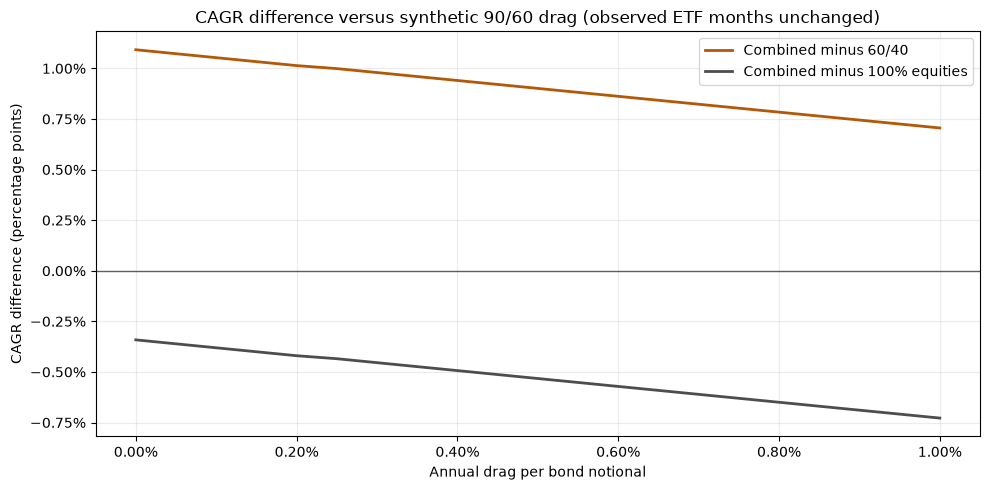

In [6]:
from matplotlib.ticker import PercentFormatter


def summary_metrics(monthly_returns, cash_returns):
    wealth = (1 + monthly_returns).cumprod()
    wealth.loc[monthly_returns.index[0] - pd.offsets.MonthEnd(1)] = 1.0
    wealth = wealth.sort_index()
    drawdowns = wealth / wealth.cummax() - 1
    total_return = wealth.iloc[-1] - 1
    cagr = (1 + total_return) ** (12 / len(monthly_returns)) - 1
    max_drawdown = drawdowns.min()
    average_drawdown = pd.Series({
        column: series[series < 0].groupby(series.eq(0).cumsum()).min().mean()
        for column, series in drawdowns.items()
    })
    excess = monthly_returns.sub(cash_returns, axis=0)
    excess_volatility = excess.std(ddof=1).replace(0, float("nan"))
    downside = (excess.clip(upper=0).pow(2).mean() ** 0.5).replace(0, float("nan"))
    return pd.DataFrame({
        "Total return": total_return,
        "CAGR": cagr,
        "Volatility": monthly_returns.std(ddof=1) * 12 ** 0.5,
        "Max drawdown": max_drawdown,
        "Average drawdown": average_drawdown,
        "Sharpe": excess.mean() / excess_volatility * 12 ** 0.5,
        "Sortino": excess.mean() / downside * 12 ** 0.5,
        "Calmar": cagr / (-max_drawdown).replace(0, float("nan")),
    })


def format_summary(metrics):
    formatted = metrics.copy()
    for column in ["Total return", "CAGR", "Volatility", "Max drawdown", "Average drawdown"]:
        formatted[column] = metrics[column].map(lambda x: f"{x:.2%}" if pd.notna(x) else "N/A")
    for column in ["Sharpe", "Sortino", "Calmar"]:
        formatted[column] = metrics[column].map(lambda x: f"{x:.2f}" if pd.notna(x) else "N/A")
    return formatted


wealth_history = portfolio_values / initial_value
summary = summary_metrics(portfolio_returns, returns["risk_free"])
print("Average drawdown is the mean of each episode’s maximum loss, including ongoing episodes.")
print("Sharpe and Sortino use monthly USD bill returns; Sortino downside is relative to the monthly bill return.")
display(format_summary(summary))

sensitivity_returns = pd.DataFrame({
    f"Estimated {cta_management_fee:.0%}/{cta_performance_fee:.0%} gross-up": combined_returns(core_returns, managed_futures_gross),
    "Without gross-up": combined_returns(core_returns, managed_futures_no_gross),
})
print("Gross-up sensitivity: identical 90/60 allocation, proxy TER and actual DBMF splice; only historical CTA fee inversion changes.")
display(format_summary(summary_metrics(sensitivity_returns, returns["risk_free"])))

# Rates are hypothetical annual costs per unit of bond notional.
drag_grid = np.linspace(drag_sensitivity_min, drag_sensitivity_max, drag_sensitivity_points)
combined_cagr = pd.Series({
    drag: (1 + combined_returns(core_with_drag(drag), managed_futures)).prod() ** (12 / len(returns)) - 1
    for drag in drag_grid
})
cagr_differences = pd.DataFrame({
    "Combined minus 60/40": combined_cagr - summary.loc["60/40", "CAGR"],
    "Combined minus 100% equities": combined_cagr - summary.loc["100% equities", "CAGR"],
})
ax = cagr_differences.plot(figsize=(10, 5), linewidth=2,
                          color=[portfolio_colors["60/40"], portfolio_colors["100% equities"]])
ax.axhline(0, color="black", linewidth=1, alpha=0.6)
ax.set_title("CAGR difference versus synthetic 90/60 drag (observed ETF months unchanged)")
ax.set_xlabel("Annual drag per bond notional")
ax.set_ylabel("CAGR difference (percentage points)")
ax.xaxis.set_major_formatter(PercentFormatter(1))
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

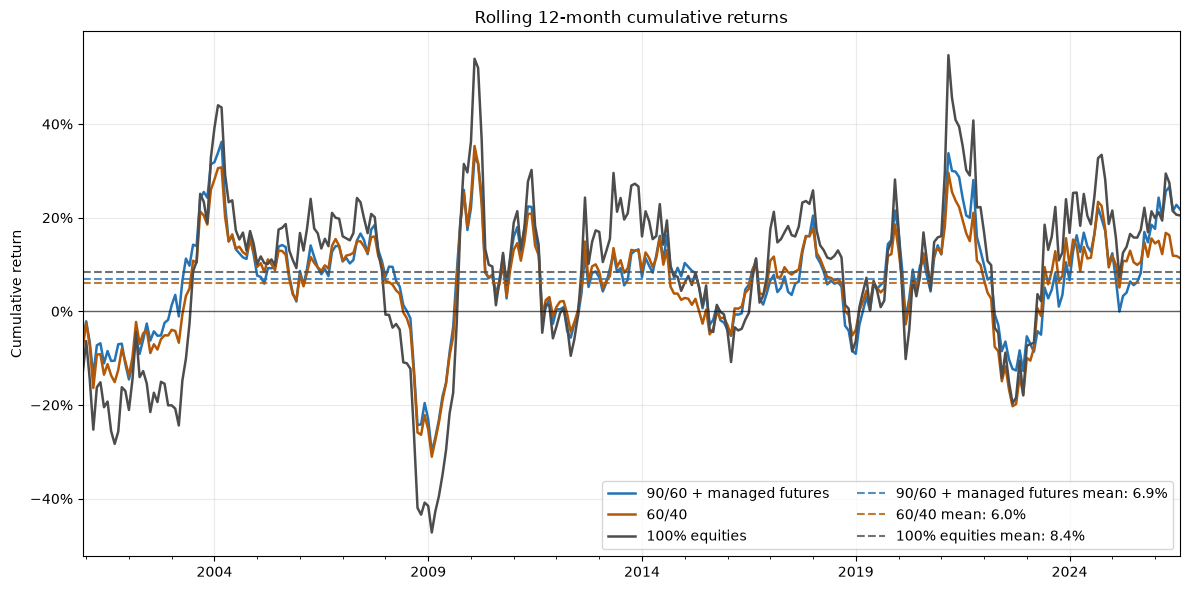

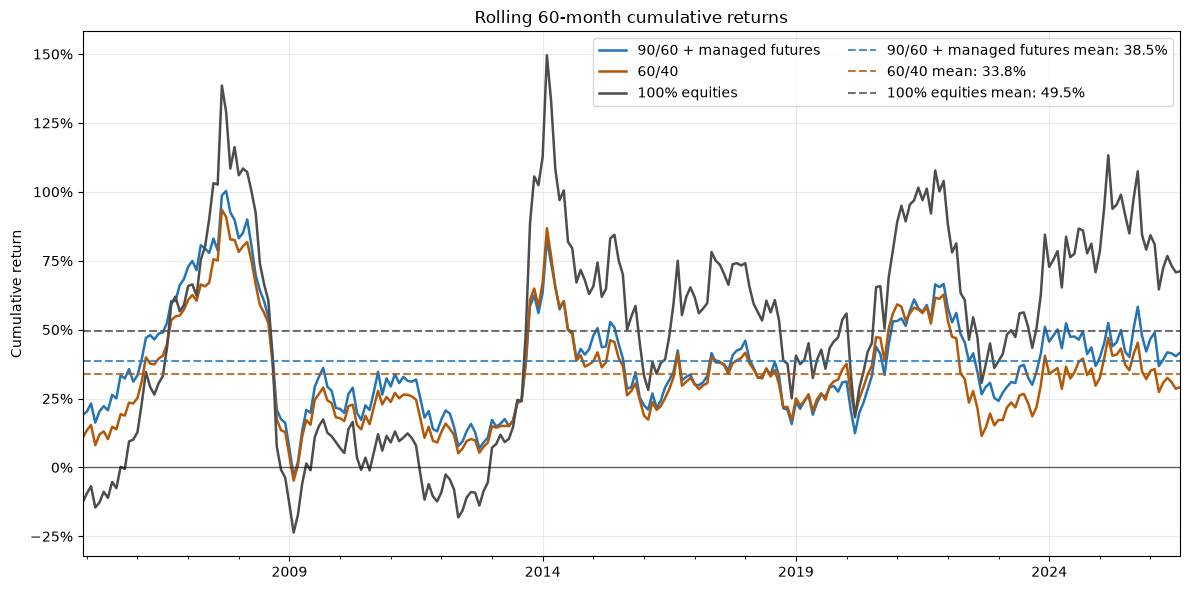

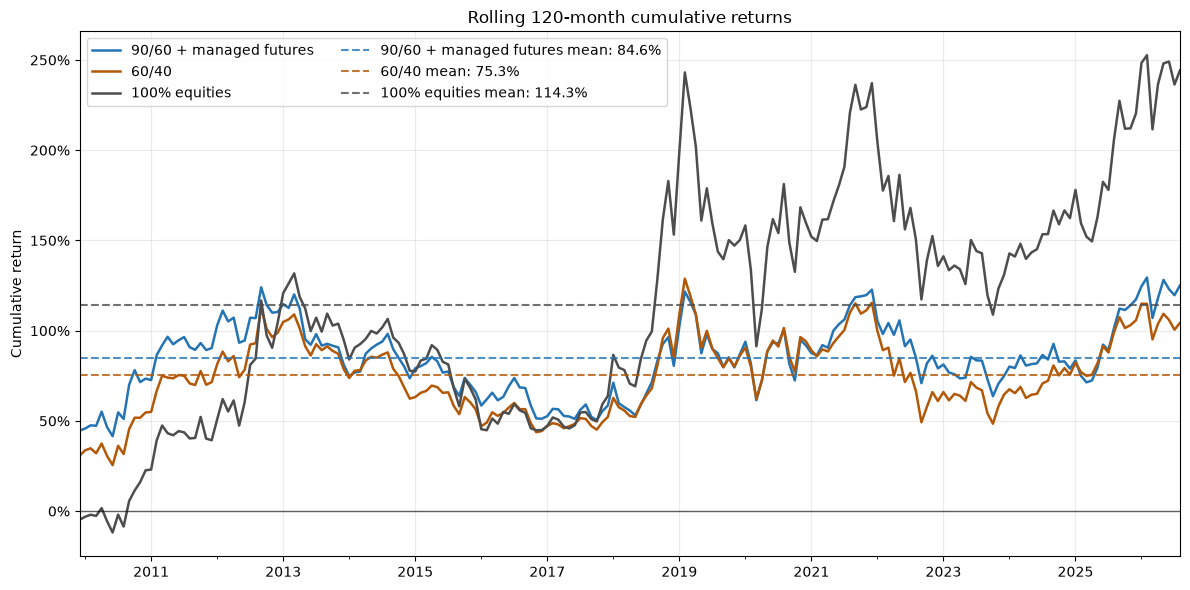

In [7]:
from matplotlib.ticker import PercentFormatter

rolling_portfolios = portfolio_returns[[combined_name, "60/40", "100% equities"]]
for months in rolling_months:
    if months > len(rolling_portfolios):
        continue
    rolling_returns = (1 + rolling_portfolios).rolling(months).apply(lambda x: x.prod() - 1, raw=True).dropna()
    ax = rolling_returns.plot(figsize=(12, 6), linewidth=1.8, color=[portfolio_colors[column] for column in rolling_returns],
                              style=[proxy_styles.get(column, "-") for column in rolling_returns])
    for line, column in zip(ax.lines, rolling_returns.columns):
        ax.axhline(rolling_returns[column].mean(), color=line.get_color(), linestyle="--", alpha=0.8,
                   label=f"{column} mean: {rolling_returns[column].mean():.1%}")
    ax.axhline(0, color="black", linewidth=1, alpha=0.6)
    ax.set_title(f"Rolling {months}-month cumulative returns")
    ax.set_xlabel("")
    ax.set_ylabel("Cumulative return")
    ax.yaxis.set_major_formatter(PercentFormatter(1))
    ax.grid(alpha=0.25)
    ax.legend(ncol=2)
    plt.tight_layout()
    plt.show()


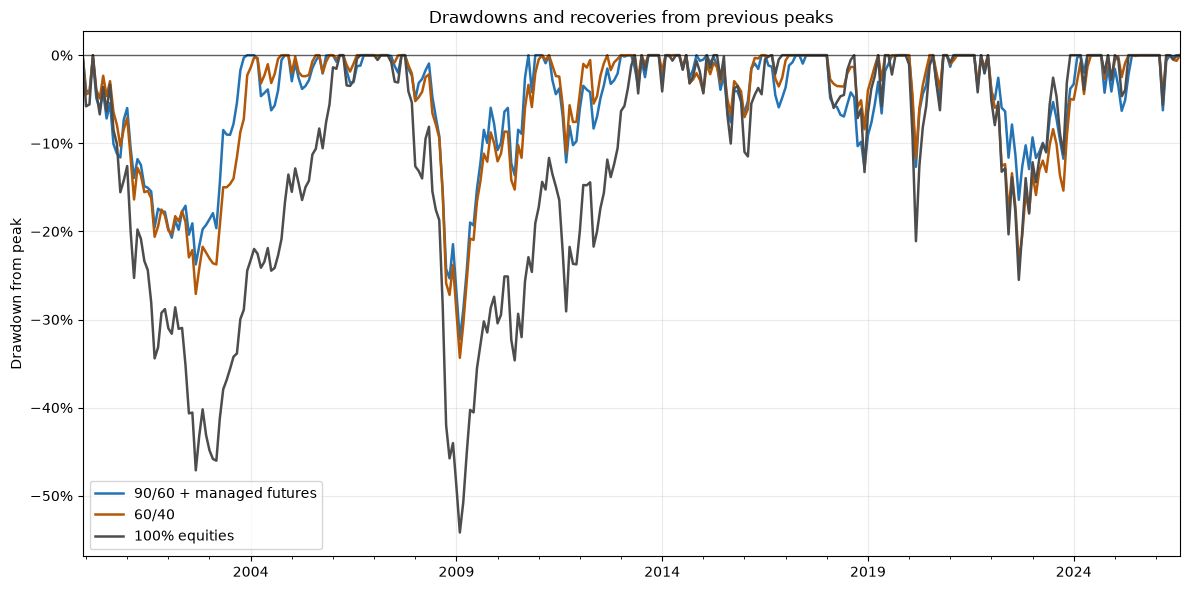

,Maximum drawdown,Peak,Trough,Recovery,Peak-to-recovery (months)
Portfolio,,,,,
90/60 + managed futures,-32.25%,2007-10,2009-02,2010-10,36
60/40,-34.35%,2007-10,2009-02,2011-02,40
100% equities,-54.18%,2007-10,2009-02,2013-05,67


In [8]:
selected_portfolios = [combined_name, "60/40", "100% equities"]
selected_wealth = wealth_history[selected_portfolios]
drawdowns = selected_wealth / selected_wealth.cummax() - 1

ax = drawdowns.plot(figsize=(12, 6), linewidth=1.8,
                    color=[portfolio_colors[column] for column in selected_portfolios])
ax.axhline(0, color="black", linewidth=1, alpha=0.6)
ax.set_title("Drawdowns and recoveries from previous peaks")
ax.set_xlabel("")
ax.set_ylabel("Drawdown from peak")
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

recovery_rows = []
for column in selected_portfolios:
    trough = drawdowns[column].idxmin()
    peak = selected_wealth.loc[:trough, column].idxmax()
    recovery = selected_wealth.loc[trough:, column]
    recovery = recovery[recovery >= selected_wealth.loc[peak, column]]
    recovery_date = recovery.index[0] if not recovery.empty else None
    months_to_recover = ((recovery_date.year - peak.year) * 12 + recovery_date.month - peak.month
                         if recovery_date is not None else None)
    recovery_rows.append({
        "Portfolio": column,
        "Maximum drawdown": f"{drawdowns.loc[trough, column]:.2%}",
        "Peak": peak.strftime("%Y-%m"),
        "Trough": trough.strftime("%Y-%m"),
        "Recovery": recovery_date.strftime("%Y-%m") if recovery_date is not None else "Not recovered",
        "Peak-to-recovery (months)": months_to_recover,
    })
display(pd.DataFrame(recovery_rows).set_index("Portfolio"))

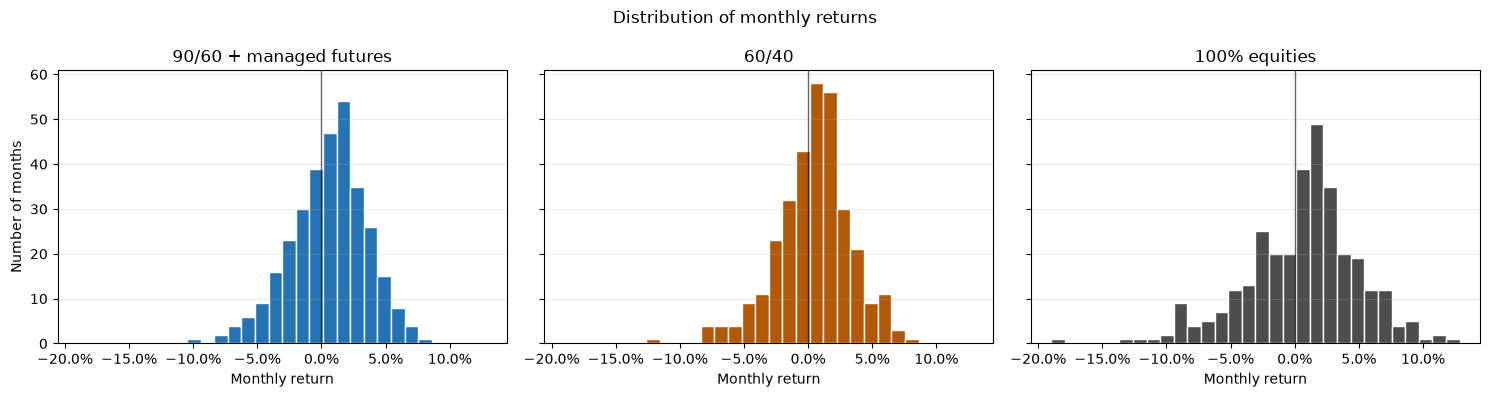

In [9]:
histogram_returns = portfolio_returns[selected_portfolios]
bins = np.linspace(histogram_returns.min().min(), histogram_returns.max().max(), histogram_bins + 1)
fig, axes = plt.subplots(1, len(selected_portfolios), figsize=(15, 4), sharex=True, sharey=True)
for ax, column in zip(axes, selected_portfolios):
    ax.hist(histogram_returns[column], bins=bins, color=portfolio_colors[column], edgecolor="white")
    ax.axvline(0, color="black", linewidth=1, alpha=0.6)
    ax.set_title(column)
    ax.set_xlabel("Monthly return")
    ax.xaxis.set_major_formatter(PercentFormatter(1))
    ax.grid(axis="y", alpha=0.25)
axes[0].set_ylabel("Number of months")
fig.suptitle("Distribution of monthly returns")
plt.tight_layout()
plt.show()

## Unhedged EUR comparison

The USD portfolios are translated using month-end USD per EUR spot rates, with no currency hedge. Before 1999, the EUR series uses the ECU as a historical proxy. Sharpe and Sortino use the USD bill return translated into EUR as the comparison return; it carries USD currency risk and is not a EUR risk-free rate.

Unhedged EUR returns: 2000-01 to 2026-08
Before 1999, EUR is represented by an ECU proxy; Sharpe and Sortino use USD bills translated to EUR, not EUR cash.
Average drawdown is the mean of each episode’s maximum loss, including ongoing episodes.


,Total return,CAGR,Volatility,Max drawdown,Average drawdown,Sharpe,Sortino,Calmar
90/60 + managed futures,323.72%,5.56%,9.29%,-30.53%,-5.02%,0.39,0.56,0.18
60/40,237.54%,4.67%,9.08%,-36.03%,-4.29%,0.31,0.44,0.13
100% equities,384.22%,6.09%,14.30%,-56.59%,-8.50%,0.33,0.46,0.11


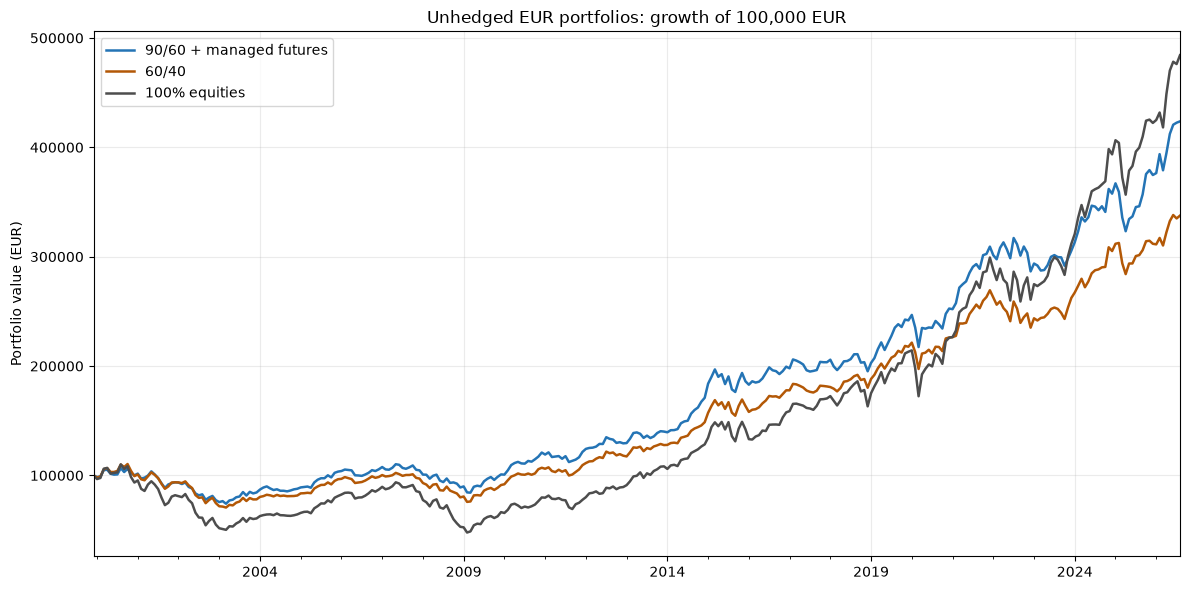

In [10]:
eur_fx = load_prices(fx_file)
eur_dates = portfolio_returns.index.insert(0, portfolio_returns.index[0] - pd.offsets.MonthEnd(1))
eur_fx = eur_fx.reindex(eur_dates)
if eur_fx.isna().any():
    raise ValueError("Missing monthly USD per EUR exchange rates in the portfolio history")
eur_fx_factor = (eur_fx.shift(1) / eur_fx).iloc[1:]
eur_returns = (1 + portfolio_returns).mul(eur_fx_factor, axis=0) - 1
eur_cash = (1 + returns["risk_free"]).mul(eur_fx_factor) - 1

eur_wealth = (1 + eur_returns).cumprod()
eur_wealth.loc[eur_dates[0]] = 1.0
eur_wealth = eur_wealth.sort_index()
eur_summary = summary_metrics(eur_returns, eur_cash)
print(f"Unhedged EUR returns: {eur_returns.index[0]:%Y-%m} to {eur_returns.index[-1]:%Y-%m}")
print("Before 1999, EUR is represented by an ECU proxy; Sharpe and Sortino use USD bills translated to EUR, not EUR cash.")
print("Average drawdown is the mean of each episode’s maximum loss, including ongoing episodes.")
display(format_summary(eur_summary))

ax = (initial_value * eur_wealth).plot(figsize=(12, 6), linewidth=1.8,
                              color=[portfolio_colors[column] for column in eur_wealth])
ax.set_title(f"Unhedged EUR portfolios: growth of {initial_value:,.0f} EUR")
ax.set_xlabel("")
ax.set_ylabel("Portfolio value (EUR)")
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## Observed-ETF comparison and execution-cost sensitivity

Only this short panel uses observed fund returns for every sleeve throughout. It is reset independently at the first common full month, with the same investor entry and turnover costs. Different exchange closing times and adjusted-close data quality remain limitations. The longer panel above is a synthetic historical experiment, not a historical investable ETF track record. See [the assumption audit](methodology/realistic_backtest.md) for each decision and source.

In [11]:
live_start = max(returns.index[0], core_actual.index[0], dbmf_actual.index[0],
                 equity_actual.index[0], bond_actual.index[0])
live_dates = returns.index[returns.index >= live_start]
if len(live_dates) >= 2:
    live_returns = comparison_returns(core_actual.reindex(live_dates), dbmf_actual.reindex(live_dates),
                                      equity_actual.reindex(live_dates), bond_actual.reindex(live_dates))
    print(f"Observed-ETF panel: {live_dates[0]:%Y-%m} to {live_dates[-1]:%Y-%m} ({len(live_dates)} months); no second fund fee or proxy drag.")
    display(format_summary(summary_metrics(live_returns, returns["risk_free"].reindex(live_dates))))
    live_fx = load_prices(fx_file).reindex(live_dates.insert(0, live_dates[0] - pd.offsets.MonthEnd(1)))
    if live_fx.isna().any():
        raise ValueError("Missing FX for the observed-ETF panel")
    live_fx_factor = (live_fx.shift(1) / live_fx).iloc[1:]
    live_eur = (1 + live_returns).mul(live_fx_factor, axis=0) - 1
    live_eur_cash = (1 + returns["risk_free"].reindex(live_dates)) * live_fx_factor - 1
    print("Observed-ETF panel in unhedged EUR; comparison cash is USD bills translated to EUR.")
    display(format_summary(summary_metrics(live_eur, live_eur_cash)))
else:
    print("The selected period has fewer than two common observed-ETF months.")

execution_rows = []
for multiplier in trading_cost_scenarios:
    sample = comparison_returns(core_returns, managed_futures, equity_net, bond_net, multiplier)
    metrics = summary_metrics(sample, returns["risk_free"])
    for name in metrics.index:
        execution_rows.append({"Cost multiplier": multiplier, "Portfolio": name,
                               "CAGR": f"{metrics.loc[name, 'CAGR']:.2%}",
                               "Max drawdown": f"{metrics.loc[name, 'Max drawdown']:.2%}"})
print("Execution-cost sensitivity: one-way entry and rebalance trading costs, not a repeated annual portfolio fee.")
display(pd.DataFrame(execution_rows).set_index(["Cost multiplier", "Portfolio"]))

Observed-ETF panel: 2024-12 to 2026-08 (21 months); no second fund fee or proxy drag.


,Total return,CAGR,Volatility,Max drawdown,Average drawdown,Sharpe,Sortino,Calmar
90/60 + managed futures,28.29%,15.30%,10.04%,-6.25%,-3.87%,1.08,1.71,2.45
60/40,20.01%,10.98%,7.92%,-4.73%,-2.06%,0.86,1.37,2.32
100% equities,33.37%,17.88%,11.50%,-5.67%,-3.42%,1.15,2.12,3.15


Observed-ETF panel in unhedged EUR; comparison cash is USD bills translated to EUR.


,Total return,CAGR,Volatility,Max drawdown,Average drawdown,Sharpe,Sortino,Calmar
90/60 + managed futures,16.85%,9.31%,10.72%,-11.92%,-4.56%,1.06,1.66,0.78
60/40,9.30%,5.22%,8.26%,-9.12%,-2.89%,0.83,1.30,0.57
100% equities,21.48%,11.76%,11.94%,-12.25%,-3.56%,1.14,2.07,0.96


Execution-cost sensitivity: one-way entry and rebalance trading costs, not a repeated annual portfolio fee.


CAGR Max drawdown
Cost multiplier Portfolio                                  
0.5             90/60 + managed futures  6.15%      -32.23%
                60/40                    5.24%      -34.34%
                100% equities            6.67%      -54.18%
1.0             90/60 + managed futures  6.13%      -32.25%
                60/40                    5.23%      -34.35%
                100% equities            6.67%      -54.18%
2.0             90/60 + managed futures  6.10%      -32.30%
                60/40                    5.22%      -34.37%
                100% equities            6.66%      -54.18%

## Rolling correlation and equity market regime

The correlation window, trailing equity-return window and bull/bear threshold are configured in cell 2. Shading uses only information available at each month-end; months without a full trailing window have no label.

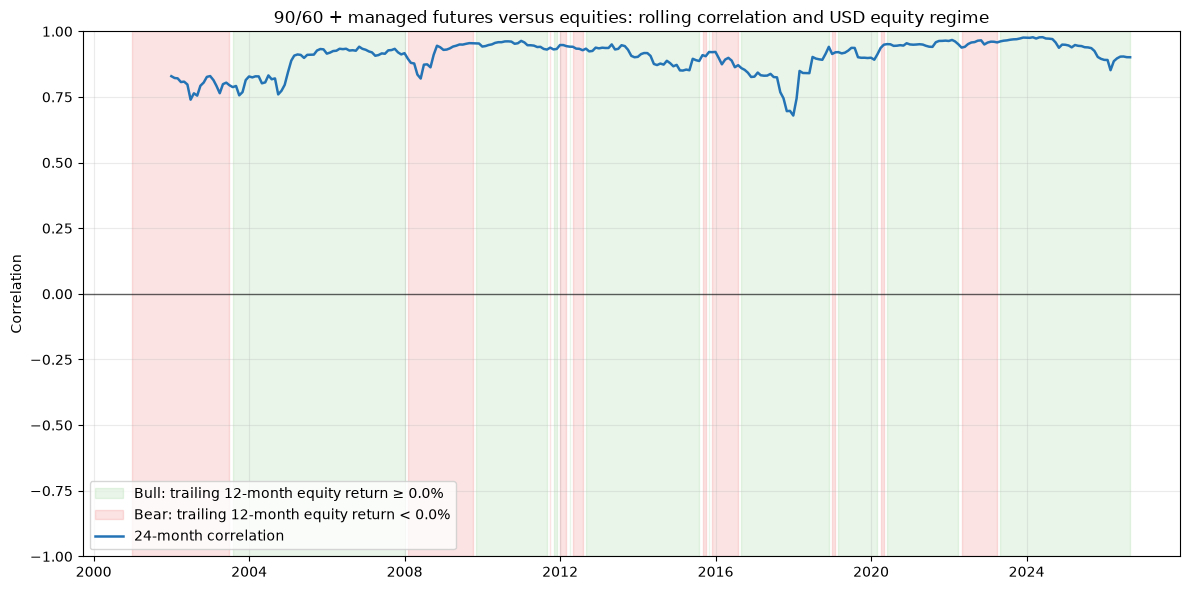

In [12]:
rolling_correlation = portfolio_returns[combined_name].rolling(correlation_months).corr(portfolio_returns["100% equities"])
equity_trailing_return = (1 + portfolio_returns["100% equities"]).rolling(regime_months).apply(np.prod, raw=True) - 1
bull_market = equity_trailing_return.ge(bull_return_threshold) & equity_trailing_return.notna()
bear_market = equity_trailing_return.lt(bull_return_threshold)

fig, ax = plt.subplots(figsize=(12, 6))
ax.fill_between(portfolio_returns.index, -1, 1, where=bull_market, step="mid",
                color="#4daf4a", alpha=0.12, label=f"Bull: trailing {regime_months}-month equity return ≥ {bull_return_threshold:.1%}")
ax.fill_between(portfolio_returns.index, -1, 1, where=bear_market, step="mid",
                color="#e41a1c", alpha=0.12, label=f"Bear: trailing {regime_months}-month equity return < {bull_return_threshold:.1%}")
ax.plot(rolling_correlation.index, rolling_correlation, color=portfolio_colors[combined_name],
        linewidth=1.8, label=f"{correlation_months}-month correlation")
ax.axhline(0, color="black", linewidth=1, alpha=0.6)
ax.set_ylim(-1, 1)
ax.set_title("90/60 + managed futures versus equities: rolling correlation and USD equity regime")
ax.set_xlabel("")
ax.set_ylabel("Correlation")
ax.grid(alpha=0.25)
ax.legend(loc="lower left")
plt.tight_layout()
plt.show()